In [ ]:
!pip install opencv-python numpy

### Explanation: Environment Setup
This initial step prepares our workspace. We install **OpenCV** (`opencv-python`), the industry-standard computer vision library, alongside **NumPy**, which is essential for managing image matrices.

```
+------------------+       +----------------------+
|   opencv-python  |  -->  | Image Processing APIs|
+------------------+       +----------------------+
|       numpy      |  -->  | High-performance Math|
+------------------+       +----------------------+
```

In [ ]:
import cv2
import numpy as np
from google.colab import patches
from google.colab import files

### Explanation: Library Imports
Here, we import the core modules required for the operations:
* **`cv2`**: Accesses OpenCV's image manipulation algorithms.
* **`numpy` (as `np`)**: Used for multidimensional matrix manipulations (since OpenCV loads images as NumPy arrays).
* **`patches`**: A Colab-specific utility (`cv2_imshow`) designed to display images correctly within the notebook without crashing the backend runtime.

Please upload an image file (e.g., JPEG, PNG):


Saving images.jpeg to images.jpeg

--- 0. Original Image ---


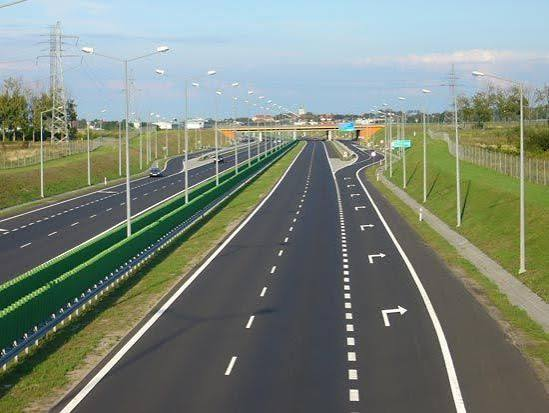

In [ ]:
# --- STEP 0: Upload & Load Input Image ---
print("Please upload an image file (e.g., JPEG, PNG):")
uploaded = files.upload()

# Automatically fetch the name of the file you just uploaded
if uploaded:
    image_path = list(uploaded.keys())[0]
    img = cv2.imread(image_path)
else:
    # Fallback if upload fails or is skipped
    image_path = "photo.jpg"
    img = cv2.imread(image_path)

if img is None:
    print(f"Error: Could not load image. Please make sure you uploaded a valid image file.")
else:
    print("\n--- 0. Original Image ---")
    patches.cv2_imshow(img)
    height, width = img.shape[:2]

### Explanation: Loading and Rendering an Image
This step initiates our image processing pipeline.
1. **File Upload**: Prompting a file dialog allowing you to input any image from your computer.
2. **Matrix Translation**: OpenCV reads the image into a 3D NumPy array containing coordinate values mapped to **BGR** (Blue, Green, Red) intensity levels.

```
  Image Grid Coordinate Map:
   (0,0)---------------+
     |   [B, G, R]     |  <-- Each pixel is represented by 3 color channels
     |                 |
     +-----------------(width, height)
```


--- 1. Resized & Scaled (50%) ---


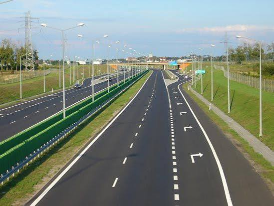

In [ ]:
# --- STEP 1: Resizing & Scaling ---
print("\n--- 1. Resized & Scaled (50%) ---")
resized_img = cv2.resize(img, (width // 2, height // 2), interpolation=cv2.INTER_LINEAR)
patches.cv2_imshow(resized_img)

### Explanation: Resizing and Scaling
Image scaling changes the dimensions of the pixel grid.
* We compute a new width and height representing exactly **50%** of the original resolution.
* **`cv2.INTER_LINEAR` (Bilinear Interpolation)**: Estimates new pixel values by calculating the weighted average of the closest $2 \times 2$ neighborhood of pixels to preserve continuous textures cleanly.

```
Original Grid (W x H)         Resized Grid (0.5W x 0.5H)
  +---+---+                  
  | A | B |                    +---+
  +---+---+         --->       | X |  <-- Interpolated value
  | C | D |                    +---+
  +---+---+
```


--- 2. Cropped Region (Central 50%) ---


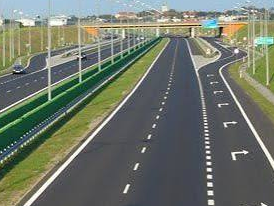

In [ ]:
# --- STEP 2: Cropping ---
print("\n--- 2. Cropped Region (Central 50%) ---")
start_y, start_x = int(height * 0.25), int(width * 0.25)
end_y, end_x = int(height * 0.75), int(width * 0.75)
cropped_img = img[start_y:end_y, start_x:end_x]
patches.cv2_imshow(cropped_img)

### Explanation: Cropping
Cropping isolates a Region of Interest (ROI).
* Because OpenCV images are structural NumPy arrays, we perform cropping using basic Python slice indexing: `img[start_y:end_y, start_x:end_x]`.
* This slice isolates the **central 50% region** of the frame by slicing from 25% to 75% along both dimensions.


--- 3. Rotated (45 deg) & Flipped ---


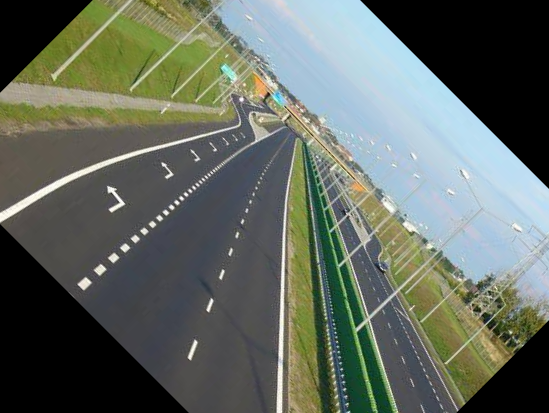

In [ ]:
# --- STEP 3: Rotation & Flipping ---
print("\n--- 3. Rotated (45 deg) & Flipped ---")
center = (width // 2, height // 2)
rotation_matrix = cv2.getRotationMatrix2D(center, angle=45, scale=1.0)
rotated_img = cv2.warpAffine(img, rotation_matrix, (width, height))
flipped_img = cv2.flip(rotated_img, 1)
patches.cv2_imshow(flipped_img)

### Explanation: Rotation & Flipping
This stage executes two consecutive spatial transformations:
1. **Rotation Matrix**: `cv2.getRotationMatrix2D` constructs a $2 \times 3$ affine transformation matrix using a center point, a rotation angle ($45^\circ$), and a scaling coefficient.
2. **Warp Affine**: `cv2.warpAffine` remaps the pixel coordinates based on that matrix.
3. **Flipping**: `cv2.flip(..., 1)` flips the coordinates along the vertical axis (y-axis) to create a horizontal mirror effect.


--- 4a. Affine Transform (Shear) ---


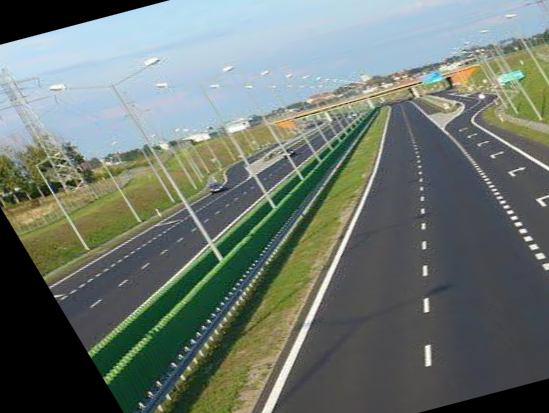

In [ ]:
# --- STEP 4a: Affine Transform (Shearing / Shifting) ---
print("\n--- 4a. Affine Transform (Shear) ---")
pts_src_affine = np.float32([[50, 50], [200, 50], [50, 200]])
pts_dst_affine = np.float32([[10, 100], [200, 50], [100, 250]])
affine_matrix = cv2.getAffineTransform(pts_src_affine, pts_dst_affine)
affine_img = cv2.warpAffine(img, affine_matrix, (width, height))
patches.cv2_imshow(affine_img)

### Explanation: Affine Transform (Shearing & Mapping)
An **Affine Transform** is a geometric transformation that preserves collinearity and ratios of distances. Parallel lines remain parallel after transformation.
* We define three control points in the input coordinate space (`pts_src_affine`) and map them to three targets in the output space (`pts_dst_affine`).
* `cv2.getAffineTransform` computes the resulting equations to perform complex shearing and stretching.


--- 4b. Perspective Transform ---


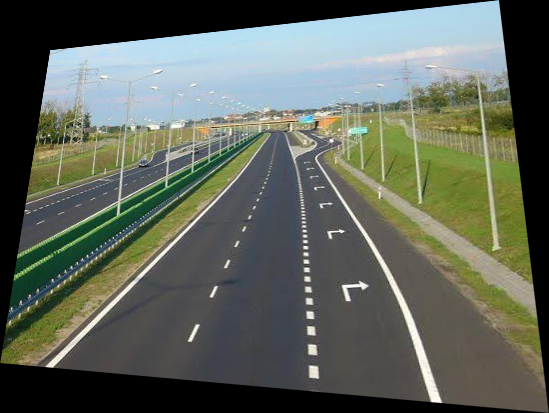


All steps completed successfully!


In [ ]:
# --- STEP 4b: Perspective Transform (3D-like warp) ---
print("\n--- 4b. Perspective Transform ---")
pts_src_perspective = np.float32([[0, 0], [width, 0], [width, height], [0, height]])
pts_dst_perspective = np.float32([[50, 50], [width - 50, 0], [width, height], [0, height - 50]])
perspective_matrix = cv2.getPerspectiveTransform(pts_src_perspective, pts_dst_perspective)
perspective_img = cv2.warpPerspective(img, perspective_matrix, (width, height))
patches.cv2_imshow(perspective_img)

print("\nAll steps completed successfully!")

### Explanation: Perspective Transform (3D Projection)
Unlike Affine transforms, a **Perspective Transform** does not preserve parallel lines, allowing you to simulate depth, tilt, and 3D projections.
* We map **four corners** of the source image to target coordinates using a $3 \times 3$ perspective transformation matrix via `cv2.getPerspectiveTransform` and project them using `cv2.warpPerspective`.

```
  Affine (3 points)          Perspective (4 points)
    +---+   +---+              +---+   +---/
    |   | -> \   \             |   | -> |  /
    +---+     +---+            +---+   +--/
```

--- 1. Grayscale Color Space ---


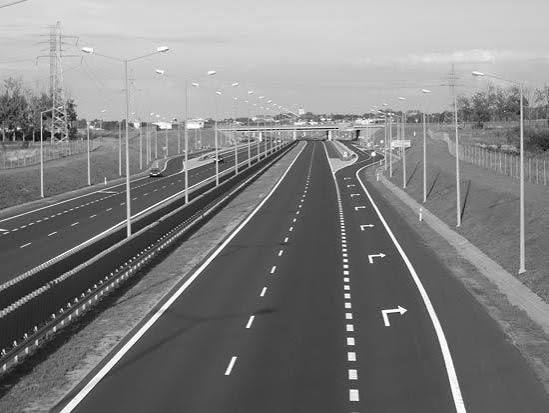

--- 2. HSV Color Space ---


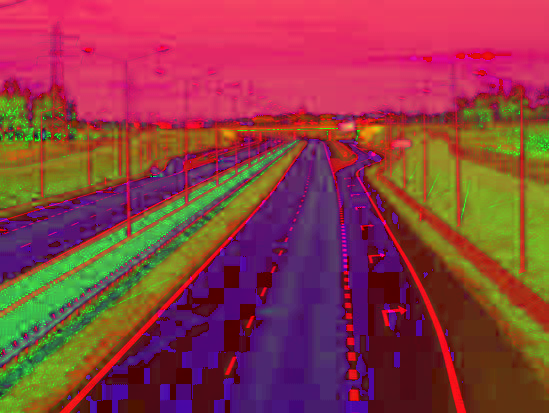

--- 3. LAB Color Space ---


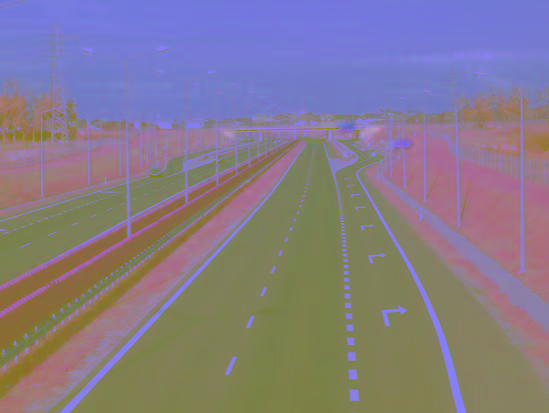

--- 4. CMYK Color Space (Rendered via RGB conversion) ---


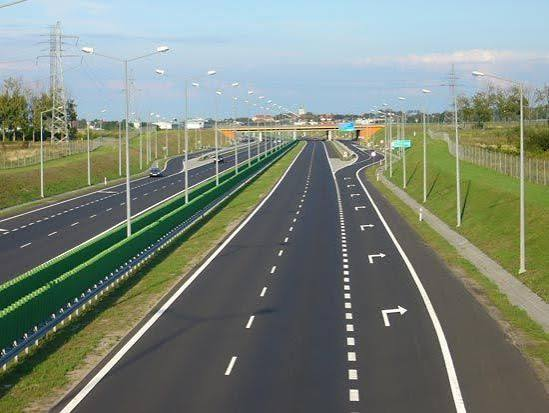

In [ ]:
if 'img' in locals() and img is not None:
    # 1. Grayscale Conversion (Standard luminance extraction)
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    print("--- 1. Grayscale Color Space ---")
    patches.cv2_imshow(gray_img)

    # 2. HSV (Hue, Saturation, Value - ideal for color filtering & tracking)
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    print("--- 2. HSV Color Space ---")
    patches.cv2_imshow(hsv_img)

    # 3. LAB (Lightness, A, B - mimics human perception of color differences)
    lab_img = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    print("--- 3. LAB Color Space ---")
    patches.cv2_imshow(lab_img)

    # 4. CMYK (Cyan, Magenta, Yellow, Key/Black - converted using Pillow since OpenCV doesn't native-render CMYK)
    from PIL import Image
    pil_img = Image.open(image_path).convert('RGB')
    cmyk_img = pil_img.convert('CMYK')
    # Convert back to RGB format for Google Colab display
    cmyk_display = np.array(cmyk_img.convert('RGB'))
    cmyk_display_bgr = cv2.cvtColor(cmyk_display, cv2.COLOR_RGB2BGR)
    print("--- 4. CMYK Color Space (Rendered via RGB conversion) ---")
    patches.cv2_imshow(cmyk_display_bgr)
else:
    print("Please run Cell 1 first to load the image.")

### Explanation: Exploring Color Spaces
Color spaces are alternative coordinate systems used to quantify and express color values:
* **Grayscale**: Compresses BGR color into a single intensity channel representing luminance.
* **HSV (Hue, Saturation, Value)**: Separates color type (Hue), intensity of color (Saturation), and brightness (Value). This structure makes HSV highly resilient to shifting lighting conditions.
* **LAB**: Segregates lightness (L) from color opponent channels (A/B), closely aligning with human color perception mechanics.
* **CMYK**: Designed for physical ink printing; converted here through PIL since OpenCV processes digital screens in RGB/BGR.

--- Brightness & Contrast (Contrast: 1.3, Brightness: 30) ---


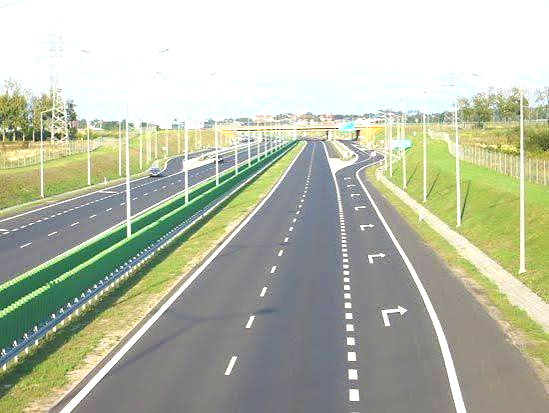

--- Gamma Correction (Gamma = 1.8) ---


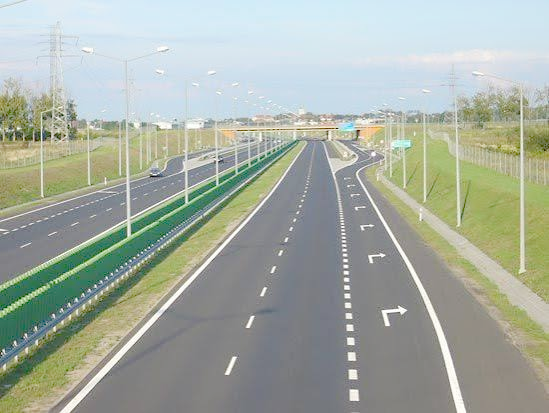

--- Standard Histogram Equalization (Grayscale) ---


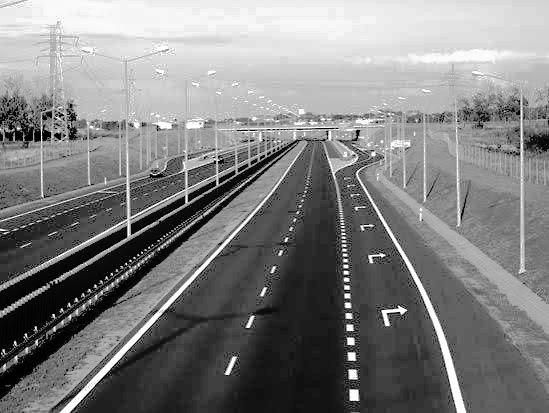

--- CLAHE (Adaptive Contrast Equalization) ---


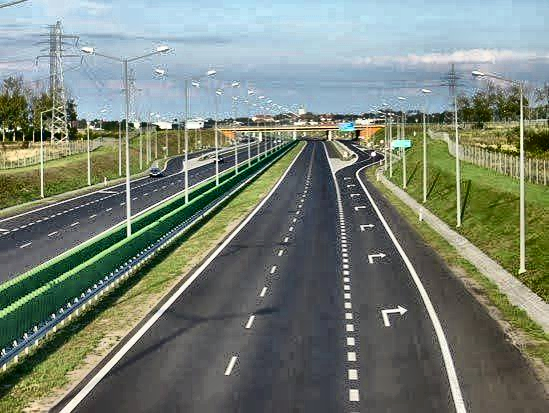

In [ ]:
if 'img' in locals() and img is not None:
    # 1. Linear Brightness & Contrast Adjustment
    # alpha controls contrast (1.0 = normal, >1.0 = higher contrast), beta controls brightness (-100 to 100)
    alpha, beta = 1.3, 30
    contrast_bright_img = cv2.convertScaleAbs(img, alpha=alpha, beta=beta)
    print(f"--- Brightness & Contrast (Contrast: {alpha}, Brightness: {beta}) ---")
    patches.cv2_imshow(contrast_bright_img)

    # 2. Gamma Correction (Non-linear brightness adjustment for shadows/highlights)
    gamma = 1.8
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype("uint8")
    gamma_img = cv2.LUT(img, table)
    print(f"--- Gamma Correction (Gamma = {gamma}) ---")
    patches.cv2_imshow(gamma_img)

    # 3. Standard Histogram Equalization (Boosts contrast globally on grayscale)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    equalized_gray = cv2.equalizeHist(gray)
    print("--- Standard Histogram Equalization (Grayscale) ---")
    patches.cv2_imshow(equalized_gray)

    # 4. CLAHE (Contrast Limited Adaptive Histogram Equalization) - local contrast for color images
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    merged_lab = cv2.merge((cl, a_channel, b_channel))
    clahe_img = cv2.cvtColor(merged_lab, cv2.COLOR_LAB2BGR)
    print("--- CLAHE (Adaptive Contrast Equalization) ---")
    patches.cv2_imshow(clahe_img)
else:
    print("Please run Cell 1 first.")

### Explanation: Brightness, Contrast, and Histograms
These techniques enhance structural details by adjusting brightness and contrast:
1. **Linear Adjustment**: Scales pixel intensities dynamically using $g(x) = \alpha \cdot f(x) + \beta$.
2. **Gamma Correction**: Applies a non-linear power-law curve to compress highlights and expand shadows.
3. **Histogram Equalization**: Spreads the most frequent intensity values out to maximize overall contrast.
4. **CLAHE**: Divides the image into smaller $8 \times 8$ tiles, equalizing each tile locally to prevent noise amplification while keeping global illumination balanced.

--- Binary Color Mask ---


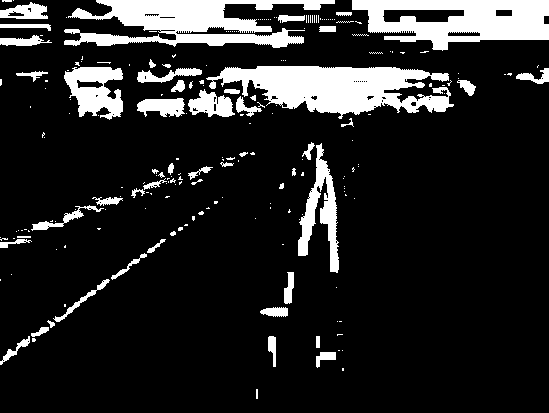

--- Isolated Color Filtering Result ---


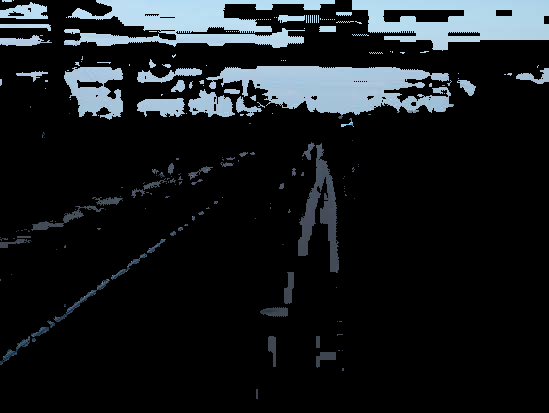

--- Color Tinting (Warm Tone Boost) ---


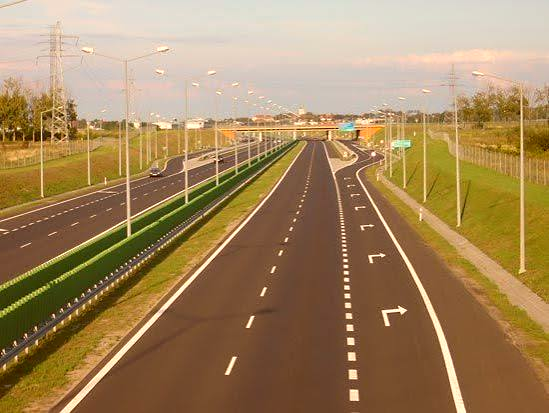

In [ ]:
if 'img' in locals() and img is not None:
    # 1. Color Filtering & Masking (Isolating a specific color range using HSV)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Define lower and upper HSV boundaries for blue color (change these values for green/red screening)
    lower_bound = np.array([100, 50, 50])
    upper_bound = np.array([140, 255, 255])

    # Create binary mask (matched colors turn white, others turn black)
    mask = cv2.inRange(hsv, lower_bound, upper_bound)
    print("--- Binary Color Mask ---")
    patches.cv2_imshow(mask)

    # Apply mask to extract only the isolated color elements
    masked_result = cv2.bitwise_and(img, img, mask=mask)
    print("--- Isolated Color Filtering Result ---")
    patches.cv2_imshow(masked_result)

    # 2. Color Tinting (Applying a warm sepia/orange tone shift)
    tinted = img.copy()
    b_channel, g_channel, r_channel = cv2.split(tinted)

    # Boost Red, slightly reduce Blue
    r_channel = cv2.add(r_channel, 40)
    b_channel = cv2.subtract(b_channel, 30)

    tinted = cv2.merge((b_channel, g_channel, r_channel))
    print("--- Color Tinting (Warm Tone Boost) ---")
    patches.cv2_imshow(tinted)
else:
    print("Please run Cell 1 first.")

### Explanation: Color Masking and Tinting
1. **Color Masking**: Isolates specific ranges in the HSV space (in this case, blue tones). Pixels within bounds become white ($255$), while others become black ($0$), acting as an overlay stencil via `cv2.bitwise_and`.
2. **Tinting**: Separates the image into individual blue, green, and red layers, scales the intensity of specific channels (increasing red, decreasing blue), and merges them back together to warm up the image's overall tone.

--- 1. Gaussian Blur ---


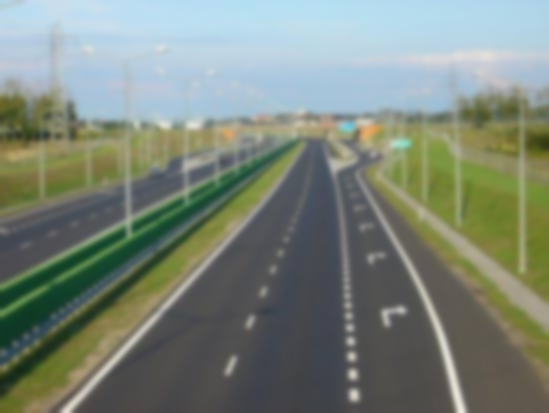

--- 2. Median Blur ---


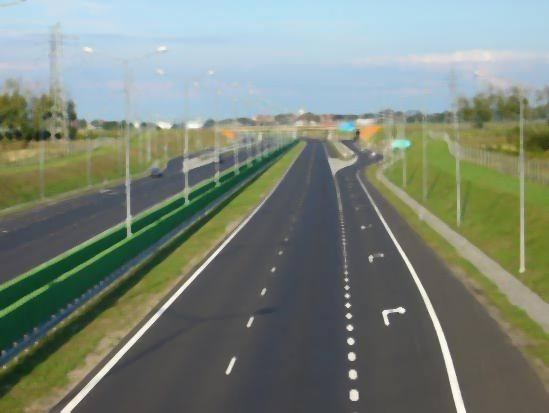

--- 3. Bilateral Filter (Edge-Preserving Denoising) ---


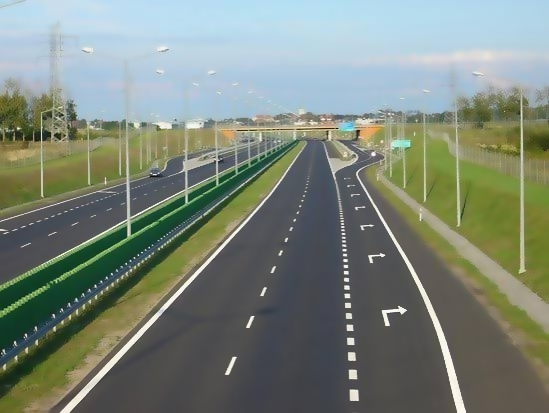

In [ ]:
if 'img' in locals() and img is not None:
    # 1. Gaussian Blur (smooths overall grain across the image)
    gaussian_img = cv2.GaussianBlur(img, (15, 15), 0)
    print("--- 1. Gaussian Blur ---")
    patches.cv2_imshow(gaussian_img)

    # 2. Median Blur (exceptional at removing 'salt and pepper' pixel noise)
    median_img = cv2.medianBlur(img, 5)
    print("--- 2. Median Blur ---")
    patches.cv2_imshow(median_img)

    # 3. Bilateral Filter (smooths noise while keeping sharp edges crisp)
    bilateral_img = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)
    print("--- 3. Bilateral Filter (Edge-Preserving Denoising) ---")
    patches.cv2_imshow(bilateral_img)
else:
    print("Please ensure your image is loaded from the previous steps.")

### Explanation: Image Smoothing and Denoising Filters
Filtering is used to reduce noise and grain within images:
* **Gaussian Blur**: Applies a weighted average based on a Gaussian bell curve kernel, smoothing out fine high-frequency details.
* **Median Blur**: Replaces each central pixel with the median value of all neighboring pixels in its window. This is highly effective at eliminating sharp, isolated salt-and-pepper noise.
* **Bilateral Filter**: Looks at both spatial distance and pixel value differences to blur homogeneous regions while fully preserving sharp edge structures.

```
   [Blur Kernel]                 [Bilateral Kernel]
 Smooths everything        Smooths but stops at sharp edges
     +-------+                     +---|-/
     | (___) |                     |   |/
     +-------+                     +---/-
```

--- 1. Canny Edge Detection ---


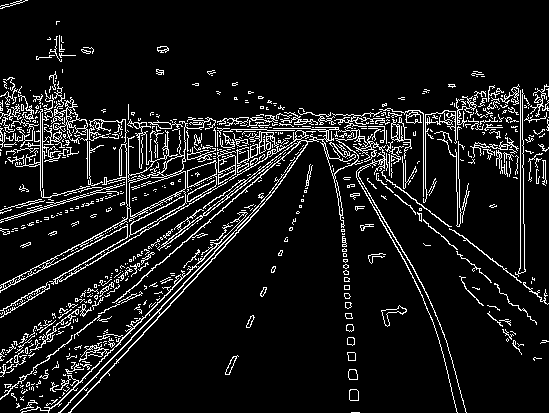

--- 2. Sobel Gradient Edge Detection ---


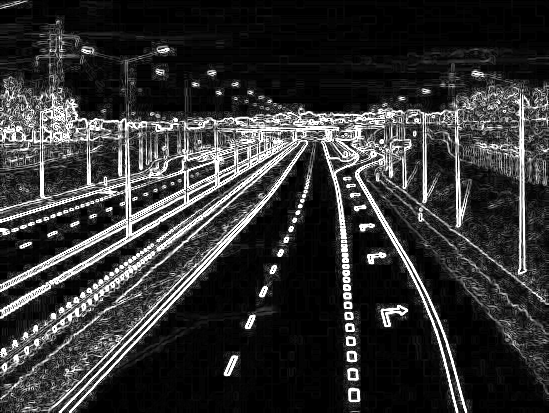

--- 3. Laplacian Edge Detection ---


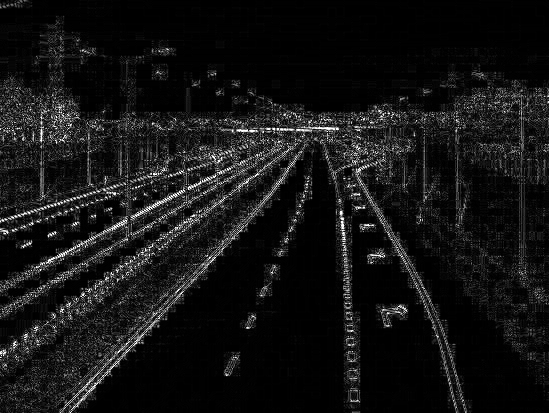

In [ ]:
if 'img' in locals() and img is not None:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Canny Edge Detection (detects strong structural boundaries cleanly)
    canny_img = cv2.Canny(gray, 100, 200)
    print("--- 1. Canny Edge Detection ---")
    patches.cv2_imshow(canny_img)

    # 2. Sobel Filter (computes directional intensity gradients in X and Y axes)
    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_combined = cv2.magnitude(sobelx, sobely)
    sobel_combined = cv2.convertScaleAbs(sobel_combined)
    print("--- 2. Sobel Gradient Edge Detection ---")
    patches.cv2_imshow(sobel_combined)

    # 3. Laplacian Filter (measures the second derivative to highlight rapid intensity shifts)
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    laplacian_img = cv2.convertScaleAbs(laplacian)
    print("--- 3. Laplacian Edge Detection ---")
    patches.cv2_imshow(laplacian_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Edge Detection Filters
Edges mark rapid boundaries where light intensity changes sharply:
* **Canny**: Applies multi-stage noise filtering, calculates spatial gradients, and uses non-maximum suppression along with hysteresis thresholding to find thin, clean structural lines.
* **Sobel**: Computes first-order derivative gradients along horizontal ($X$) and vertical ($Y$) planes independently.
* **Laplacian**: Computes a second-order derivative mapping to trace sudden changes in gradient directions.

--- 1. Sharpened Image ---


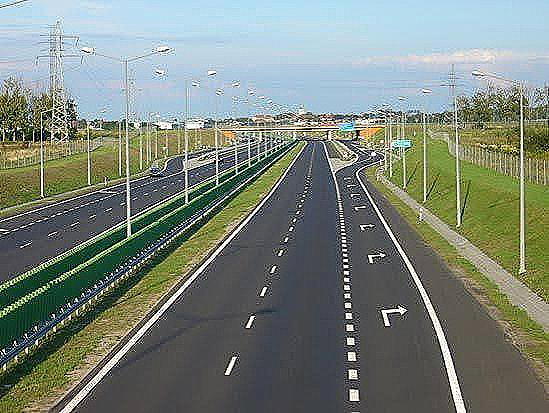

--- 2. Embossed Effect ---


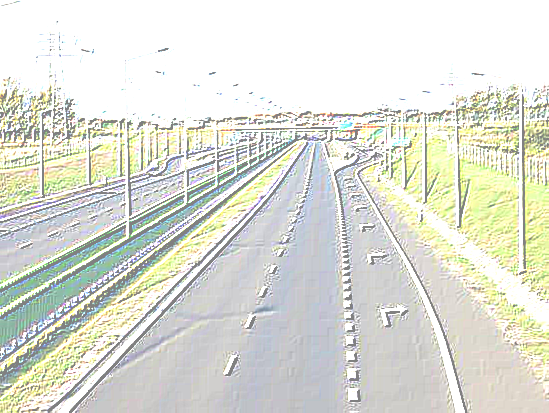

In [ ]:
if 'img' in locals() and img is not None:
    # 1. Custom Sharpening Kernel (accentuates local contrasts and fine textures)
    sharpen_kernel = np.array([[0, -1, 0],
                             [-1,  5, -1],
                             [ 0, -1,  0]])
    sharpened_img = cv2.filter2D(img, -1, sharpen_kernel)
    print("--- 1. Sharpened Image ---")
    patches.cv2_imshow(sharpened_img)

    # 2. Custom Embossing Kernel (gives a carved 3D metal/stone impression)
    emboss_kernel = np.array([[-2, -1,  0],
                            [-1,  1,  1],
                            [ 0,  1,  2]])
    embossed_img = cv2.filter2D(img, -1, emboss_kernel)
    # Add a brightness offset so mid-tones don't render entirely black
    embossed_img = cv2.add(embossed_img, 128)
    print("--- 2. Embossed Effect ---")
    patches.cv2_imshow(embossed_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Custom Kernels and Convolutions
We can apply custom filters by sliding a small matrix (a **kernel**) over every pixel of the image, performing element-wise multiplication and summing the results:
* **Sharpen Kernel**: Boosts the center pixel while subtracting the values of adjacent pixels, emphasizing high-frequency differences.
* **Emboss Kernel**: Calculates directional differences on a diagonal, creating an offset 3D shadow effect.

--- Original Binary Mask ---


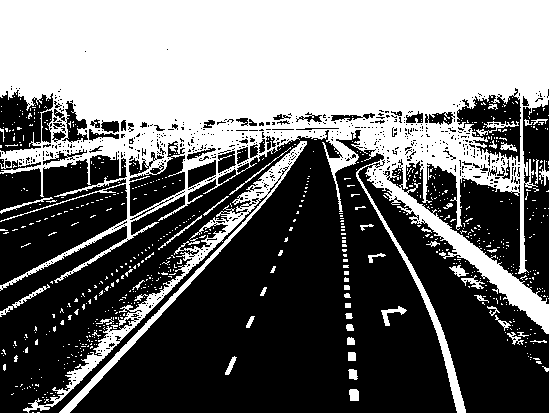

--- 1. Morphological Dilation ---


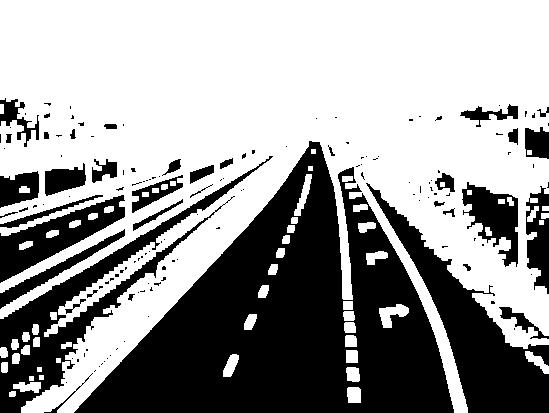

--- 2. Morphological Erosion ---


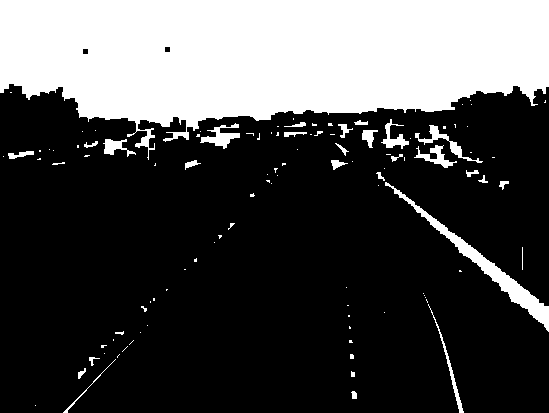

In [ ]:
if 'img' in locals() and img is not None:
    # Convert to grayscale and threshold to create a binary mask for demonstration
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, binary_mask = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
    print("--- Original Binary Mask ---")
    patches.cv2_imshow(binary_mask)

    # Define a structural element kernel matrix
    kernel = np.ones((5, 5), np.uint8)

    # 1. Dilation (expands white regions, fills small internal holes)
    dilated_img = cv2.dilate(binary_mask, kernel, iterations=1)
    print("--- 1. Morphological Dilation ---")
    patches.cv2_imshow(dilated_img)

    # 2. Erosion (shrinks white regions, strips away small floating background noise specs)
    eroded_img = cv2.erode(binary_mask, kernel, iterations=1)
    print("--- 2. Morphological Erosion ---")
    patches.cv2_imshow(eroded_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Morphological Operations
Morphological transformations process binary images based on shape:
* **Dilation**: Slides a structuring kernel over the image, turning a background pixel into a foreground pixel if at least one pixel under the kernel is white. This expands white shapes and fills in small gaps.
* **Erosion**: Shrinks white regions; a pixel under the kernel remains white only if all pixels inside the structuring element are white, which cleanly strips away tiny speckles of background noise.

```
    Input Shape        Erosion Result      Dilation Result
      +---+                +---+               +-----+
      |   |        --->    |   |       --->    |     |
      +---+                +---+               +-----+
```

--- 1. Shapes & Text Annotations ---


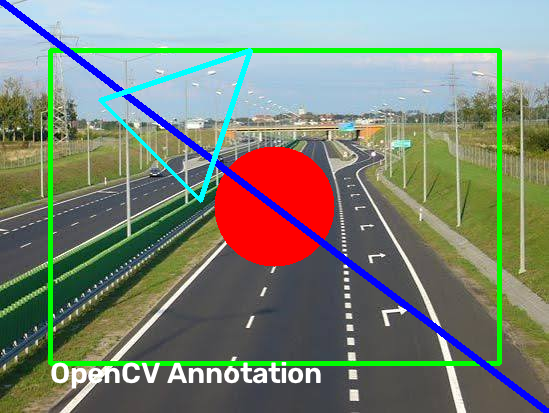

In [ ]:
if 'img' in locals() and img is not None:
    # Make a copy so we don't modify the master image permanently
    annotated_img = img.copy()
    h, w = annotated_img.shape[:2]

    # 1. Draw a Green Rectangle (e.g., bounding box)
    cv2.rectangle(annotated_img, (50, 50), (w - 50, h - 50), (0, 255, 0), thickness=3)

    # 2. Draw a Filled Red Circle in the center
    cv2.circle(annotated_img, (w // 2, h // 2), radius=60, color=(0, 0, 255), thickness=-1)

    # 3. Draw a Blue Diagonal Line across the image
    cv2.line(annotated_img, (0, 0), (w, h), (255, 0, 0), thickness=5)

    # 4. Draw a Custom Polygon
    pts = np.array([[100, 100], [250, 50], [200, 200]], np.int32)
    pts = pts.reshape((-1, 1, 2))
    cv2.polylines(annotated_img, [pts], isClosed=True, color=(255, 255, 0), thickness=3)

    # 5. Render Text Overlay
    font = cv2.FONT_HERSHEY_SIMPLEX
    cv2.putText(annotated_img, 'OpenCV Annotation', (50, h - 30), font, 1.0, (255, 255, 255), 2, cv2.LINE_AA)

    print("--- 1. Shapes & Text Annotations ---")
    patches.cv2_imshow(annotated_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Geometric Shapes and Text Annotations
This step demonstrates how to draw geometric shapes and render text directly onto an image array. This is incredibly useful for highlighting areas of interest, drawing bounding boxes, or adding labels:
* **Coordinates**: Shape coordinates are defined in pixels as `(X, Y)` pairs, starting from the top-left corner `(0, 0)`.
* **Colors**: Color parameters are defined as BGR (Blue, Green, Red) tuples.

--- 2. Semi-Transparent Watermark ---


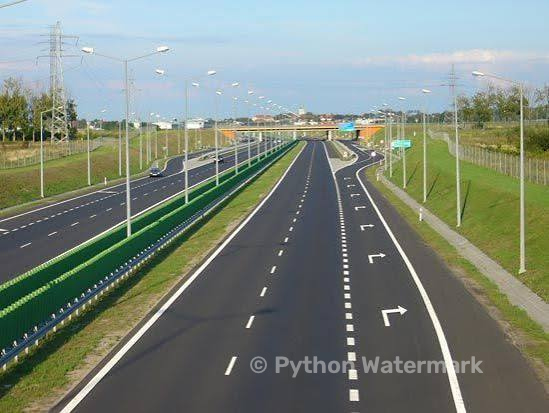

In [ ]:
if 'img' in locals() and img is not None:
    watermarked_img = img.copy()
    h, w = watermarked_img.shape[:2]

    # Create a separate duplicate overlay canvas
    overlay = watermarked_img.copy()

    # Add watermark text to the overlay canvas
    text = "© Python Watermark"
    font = cv2.FONT_HERSHEY_SIMPLEX
    # Position text near the bottom-right corner
    cv2.putText(overlay, text, (w - 300, h - 40), font, 0.8, (255, 255, 255), 2, cv2.LINE_AA)

    # Set transparency factor (alpha: 0.0 = invisible, 1.0 = fully opaque)
    alpha = 0.4

    # Blend the overlay with the original image using cv2.addWeighted
    cv2.addWeighted(overlay, alpha, watermarked_img, 1 - alpha, 0, watermarked_img)

    print("--- 2. Semi-Transparent Watermark ---")
    patches.cv2_imshow(watermarked_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Transparency Blending and Watermarks
This step applies a semi-transparent watermark to an image:
1. **Overlay Layer**: We create a duplicate copy of our image to write text onto.
2. **Linear Blending**: We apply the equation $g(x) = \alpha \cdot f_0(x) + (1 - \alpha) \cdot f_1(x)$ via `cv2.addWeighted`.
This smoothly blends the text layer with the original image, producing a clean, semi-transparent watermark.

--- 3a. Side-by-Side Composite ---


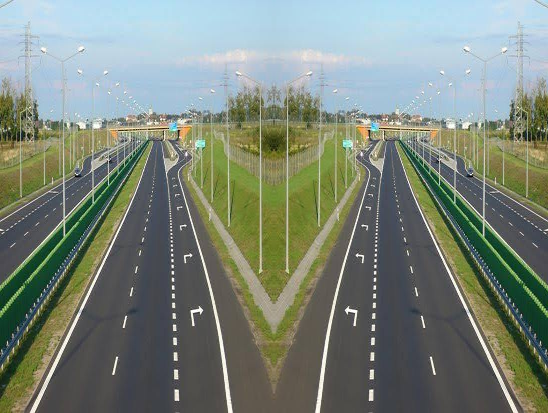

--- 3b. Alpha Blending (Color + Grayscale Fusion) ---


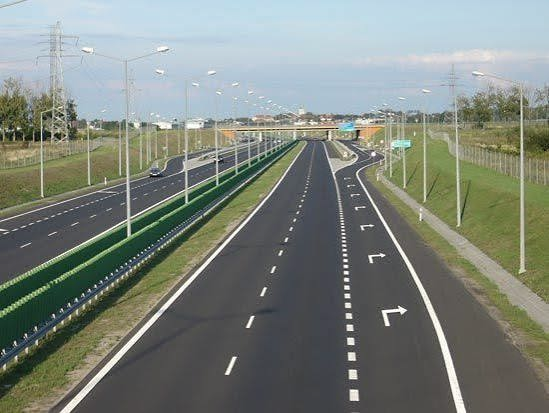

In [ ]:
if 'img' in locals() and img is not None:
    h, w = img.shape[:2]

    # 1. Side-by-Side Compositing (Horizontal Stack)
    # Resize image to half width for a neat side-by-side comparison
    half_img = cv2.resize(img, (w // 2, h))
    flipped_half = cv2.flip(half_img, 1) # Flip the right side horizontally

    side_by_side = np.hstack((half_img, flipped_half))
    print("--- 3a. Side-by-Side Composite ---")
    patches.cv2_imshow(side_by_side)

    # 2. Alpha Blending (Merging Original Image + Grayscale version into a 3-channel blend)
    gray_3ch = cv2.cvtColor(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR)

    # Blend 70% original image with 30% grayscale image
    blended_result = cv2.addWeighted(img, 0.7, gray_3ch, 0.3, 0)

    print("--- 3b. Alpha Blending (Color + Grayscale Fusion) ---")
    patches.cv2_imshow(blended_result)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Side-by-Side Comparison & Alpha Blending
1. **Horizontal Stacking (`np.hstack`)**: Combines two image arrays side-by-side. For this to work, both arrays must have the exact same height and channel dimensions.
2. **Luminance and Color Fusion**: Converts a grayscale image back into a 3-channel BGR image and blends it with the original using `cv2.addWeighted` to create a partially desaturated color effect.

--- 1. Contour Detection (Found 113 distinct objects/regions) ---


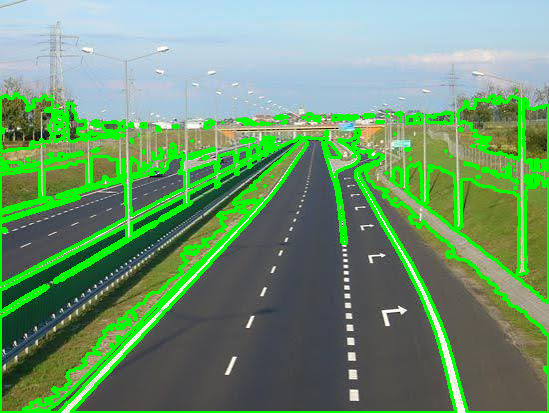

In [ ]:
if 'img' in locals() and img is not None:
    # 1. Convert to grayscale and blur to remove minor noise
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Apply thresholding to create a binary image (invert if background is light)
    _, thresh = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY_INV)

    # 3. Find external contours
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 4. Draw all detected contours onto a copy of the original image
    contour_img = img.copy()
    cv2.drawContours(contour_img, contours, -1, (0, 255, 0), 2)

    print(f"--- 1. Contour Detection (Found {len(contours)} distinct objects/regions) ---")
    patches.cv2_imshow(contour_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Contour Detection
Contours represent continuous curves or boundaries that share the same color or intensity:
1. **Thresholding**: Converts a blurred grayscale image into a binary black-and-white mask.
2. **Contour Extraction**: `cv2.findContours` traces the boundaries of white shapes against the black background.
3. **Visualization**: We draw these detected boundaries back onto the original color image using `cv2.drawContours`.

--- 2. GrabCut Foreground Segmentation ---


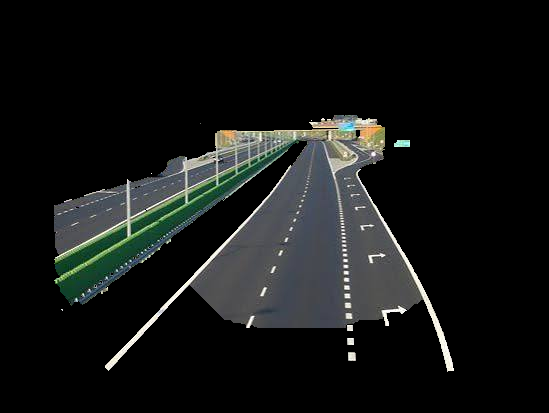

In [ ]:
if 'img' in locals() and img is not None:
    h, w = img.shape[:2]

    # Initialize a blank mask for GrabCut
    mask = np.zeros((h, w), np.uint8)

    # Internal background and foreground matrices required by OpenCV
    bgdModel = np.zeros((1, 65), np.float64)
    fgdModel = np.zeros((1, 65), np.float64)

    # Define a rectangle enclosing the main foreground object (e.g., central 80% area)
    margin_x, margin_y = int(w * 0.1), int(h * 0.1)
    rect = (margin_x, margin_y, w - (2 * margin_x), h - (2 * margin_y))

    # Execute GrabCut algorithm (iterating 5 times for refined edge separation)
    cv2.grabCut(img, mask, rect, bgdModel, fgdModel, 5, cv2.GC_INIT_WITH_RECT)

    # Filter mask to isolate definite/probable foreground pixels (values 1 and 3)
    mask2 = np.where((mask == 2) | (mask == 0), 0, 1).astype('uint8')
    segmented_img = img * mask2[:, :, np.newaxis]

    print("--- 2. GrabCut Foreground Segmentation ---")
    patches.cv2_imshow(segmented_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: GrabCut Foreground Segmentation
**GrabCut** is an interactive segmentation algorithm that extracts foreground objects from their backgrounds:
1. **Bounding Box**: We define a rectangular boundary around the main subject.
2. **Iterative Energy Minimization**: The algorithm models the foreground and background using Gaussian Mixture Models (GMMs) to find the optimal segment boundaries.
3. **Masking**: Pixels classified as background are masked to black, isolating the foreground subject.

--- 3. Template Matching (Match Confidence Score: 1.00) ---


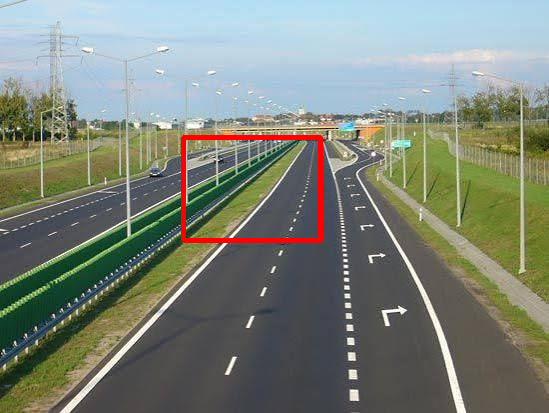

In [ ]:
if 'img' in locals() and img is not None:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape[:2]

    # Extract a patch from the image to use as a search template (e.g., central 1/4th patch)
    th, tw = h // 4, w // 4
    if th > 10 and tw > 10:
        template = gray[h // 3 : h // 3 + th, w // 3 : w // 3 + tw]

        # Perform Normalized Cross-Correlation Template Matching
        result = cv2.matchTemplate(gray, template, cv2.TM_CCOEFF_NORMED)
        min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

        # Get the top-left coordinates of the best matching location
        top_left = max_loc
        bottom_right = (top_left[0] + tw, top_left[1] + th)

        # Draw a bounding box around the matched template region
        match_img = img.copy()
        cv2.rectangle(match_img, top_left, bottom_right, (0, 0, 255), 3)

        print(f"--- 3. Template Matching (Match Confidence Score: {max_val:.2f}) ---")
        patches.cv2_imshow(match_img)
    else:
        print("Image dimensions are too small to extract a template.")
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Template Matching
Template matching searches for and finds locations in an image that match a smaller template image:
1. **Template Selection**: We crop a small region of interest to use as our search target.
2. **Sliding Window Comparison**: `cv2.matchTemplate` slides this patch across the main image, calculating a similarity score at every position.
3. **Peak Detection**: `cv2.minMaxLoc` identifies the location with the highest similarity score, where we draw a bounding box.

--- Damaged Image (Simulated Scratch) ---


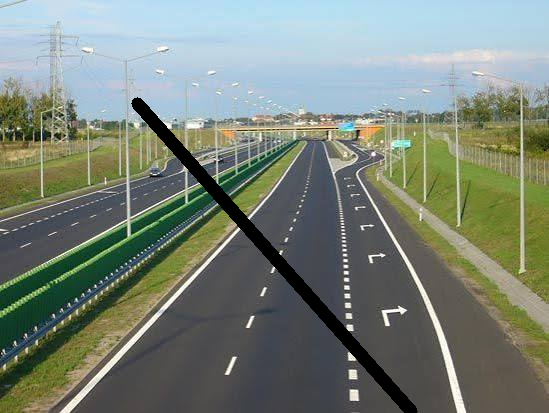

--- Restored / Inpainted Image ---


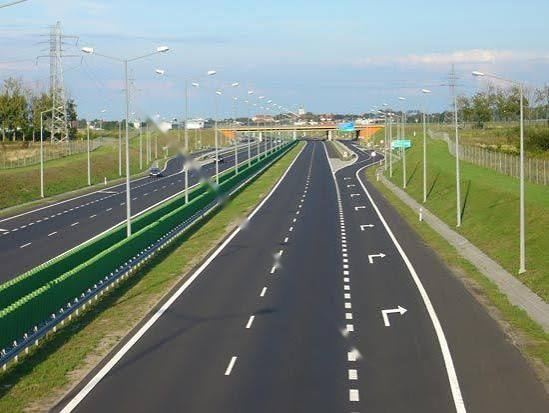

--- 2x High-Resolution Upscaled Image ---


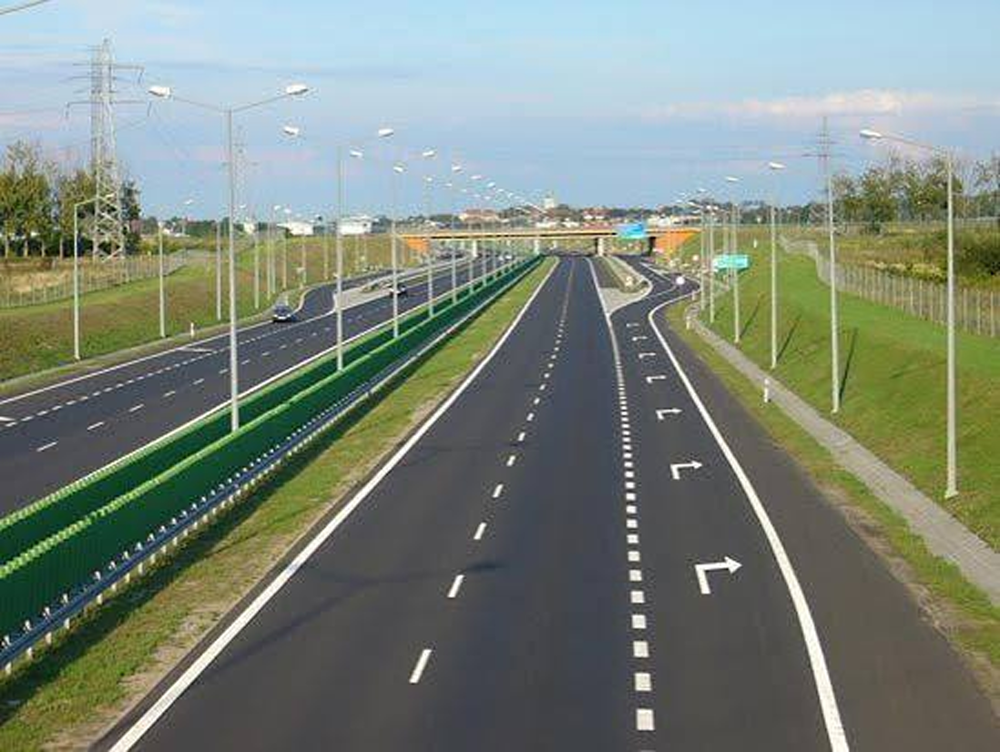

In [ ]:
if 'img' in locals() and img is not None:
    # 1. Image Inpainting: Simulate a scratch/damage and automatically repair it
    damaged_img = img.copy()
    h, w = damaged_img.shape[:2]

    # Draw a simulated scratch line across the image
    cv2.line(damaged_img, (w // 4, h // 4), (3 * w // 4, 3 * w // 4), (0, 0, 0), thickness=12)

    # Create a mask capturing the dark damage line
    gray_dmg = cv2.cvtColor(damaged_img, cv2.COLOR_BGR2GRAY)
    _, mask = cv2.threshold(gray_dmg, 15, 255, cv2.THRESH_BINARY_INV)

    print("--- Damaged Image (Simulated Scratch) ---")
    patches.cv2_imshow(damaged_img)

    # Apply Telea inpainting algorithm to automatically reconstruct missing pixels
    inpainted_img = cv2.inpaint(damaged_img, mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)
    print("--- Restored / Inpainted Image ---")
    patches.cv2_imshow(inpainted_img)

    # 2. High-Quality Upscaling / Super-Resolution (Bicubic interpolation model)
    upscaled_img = cv2.resize(img, (w * 2, h * 2), interpolation=cv2.INTER_CUBIC)
    print("--- 2x High-Resolution Upscaled Image ---")
    patches.cv2_imshow(upscaled_img)
else:
    print("Please ensure your image is loaded from previous steps.")

### Explanation: Inpainting and High-Quality Upscaling
This final cell showcases advanced image restoration techniques:
1. **Inpainting (Telea Algorithm)**: We simulate a scratch across the image and create a binary mask of the damage. The `cv2.inpaint` algorithm then restores the damaged area by writing over it using smooth, edge-aligned values from surrounding pixels.
2. **High-Quality Upscaling**: We double the size of our image using **Bicubic Interpolation (`cv2.INTER_CUBIC`)**, which fits third-degree polynomial curves over a $4 \times 4$ pixel neighborhood to keep upscaled details sharp and clean.